# Random oversampling across five model families

Post-Test exploratory extension. Fit one 1:1 random-oversampling configuration per original learned model, with identical sampled Train indices and unchanged classifier parameters. Fit each preprocessor on original Train, then resample only transformed training rows. Evaluate Validation A only. Frozen classifier/calibration/threshold decisions and prior Test results are not changed. No undersampling, class weights, tuning or threshold selection.

## Environment and repository

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import importlib.metadata
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current = Path.cwd().resolve()
ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "docs/predictor_list.csv").is_file()
     and (p / "notebooks").is_dir()), None
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
print("Repository:", ROOT)
print("Python:", platform.python_version())


Repository: C:\Users\LENOVO\OneDrive\Desktop\PTTK
Python: 3.14.6


## Load original Train and Validation A

Use streaming hashes and only required columns. No Validation B/Test probabilities are generated.

In [2]:
import gc
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss, precision_recall_curve

def file_hash(path, normalize_lf=False):
    with Path(path).open("rb") as stream:
        if not normalize_lf:
            return hashlib.file_digest(stream, "sha256").hexdigest()
        digest = hashlib.sha256()
        for line in stream:
            digest.update(line.replace(b"\r\n", b"\n"))
        return digest.hexdigest()

INPUTS = ["data/processed/research_data_weather_price_holiday_assume_utc.csv", "docs/predictor_list.csv", "data/ml_preparation/split_manifest.csv"]
hashes = {name: file_hash(ROOT / name) for name in INPUTS}
lf_hashes = {name: file_hash(ROOT / name, True) for name in INPUTS}
features = pd.read_csv(ROOT / INPUTS[1]).feature.tolist()
assert len(features) == len(set(features)) == 21
source_data = pd.read_csv(ROOT / INPUTS[0], usecols=["order_id", "is_late", *features])
manifest = pd.read_csv(ROOT / INPUTS[2], usecols=["order_id", "split"])
assert source_data.order_id.is_unique and manifest.order_id.is_unique
orders = manifest.loc[manifest.split.isin(["train", "validation_a"])]
data = orders.merge(source_data, on="order_id", how="left", validate="one_to_one", indicator=True)
assert data["_merge"].eq("both").all()
train = data.loc[data.split.eq("train")].copy().reset_index(drop=True)
val = data.loc[data.split.eq("validation_a")].copy().reset_index(drop=True)
del source_data, manifest, orders, data
gc.collect()
assert len(train) == 57449 and train.is_late.eq(1).sum() == 3720
assert len(val) == 7661 and val.is_late.eq(1).sum() == 387
assert set(train.order_id).isdisjoint(val.order_id)
cat = ["customer_state", "purchase_weekday"]
num = [name for name in features if name not in cat]
for frame in [train, val]:
    for name in cat:
        frame[name] = frame[name].map(lambda value: str(value) if pd.notna(value) else np.nan)
    for name in num:
        frame[name] = pd.to_numeric(frame[name], errors="raise").replace([np.inf, -np.inf], np.nan)
y_train = train.is_late.astype(int).to_numpy()
y_val = val.is_late.astype(int).to_numpy()


## Build the shared oversampling indices

Keep every original Train row. Randomly duplicate minority rows with replacement to 53,729 per class. The same seed-42 sample and shuffle are reused by all models.

In [3]:
rng = np.random.default_rng(42)
minority = np.flatnonzero(y_train == 1)
majority = np.flatnonzero(y_train == 0)
assert len(majority) > len(minority)
additional = rng.choice(minority, size=len(majority) - len(minority), replace=True)
sampled_indices = np.concatenate([np.arange(len(train)), additional])
rng.shuffle(sampled_indices)
y_resampled = y_train[sampled_indices]
assert len(sampled_indices) == 107458
assert int((y_resampled == 0).sum()) == int((y_resampled == 1).sum()) == 53729
multiplicity = np.bincount(sampled_indices, minlength=len(train))
assert (multiplicity >= 1).all()
assert (multiplicity[majority] == 1).all()
sample_summary = pd.DataFrame([
    dict(sample="original_train", n=len(train), not_late=int((y_train == 0).sum()), late=int((y_train == 1).sum())),
    dict(sample="oversampled_train", n=len(sampled_indices), not_late=int((y_resampled == 0).sum()), late=int((y_resampled == 1).sum())),
    dict(sample="validation_a_unchanged", n=len(val), not_late=int((y_val == 0).sum()), late=int((y_val == 1).sum())),
])
display(sample_summary)


,sample,n,not_late,late
0,original_train,57449,53729,3720
1,oversampled_train,107458,53729,53729
2,validation_a_unchanged,7661,7274,387


## Match all five baseline pipelines and record the plan

Resolve the same baseline sources used before Test. No parameters are changed. Record the resampling plan before fitting any model.

In [4]:
comparison_path = ROOT / "outputs/tables/machine_learning/ml_catboost_weighted/20261111_153704_495324/seven_model_comparison.csv"
source_map = json.loads((comparison_path.parent / "comparison_source.json").read_text(encoding="utf-8"))
baseline_comparison = pd.read_csv(comparison_path)
registry = {}
for group, names in [
    ("ml_logistic_random_forest", ["LogisticRegression", "RandomForest"]),
    ("ml_lightgbm_xgboost", ["LightGBM", "XGBoost"]),
    ("ml_catboost_dummy", ["CatBoost"]),
]:
    source = ROOT / source_map[group]
    recorded_hashes = {k.replace("\\", "/"): v for k, v in json.loads((source / "input_hashes.json").read_text(encoding="utf-8")).items()}
    assert recorded_hashes == hashes or recorded_hashes == lf_hashes
    for package, version in json.loads((source / "package_versions.json").read_text(encoding="utf-8")).items():
        if package != "python":
            assert importlib.metadata.version(package) == version
    for name in names:
        path = ROOT / "outputs/models" / group / source.name / f"{name}.joblib"
        baseline = joblib.load(path)
        parameters = baseline.named_steps["classifier"].get_params()
        assert parameters.get("class_weight") is None
        assert parameters.get("class_weights") is None
        assert parameters.get("scale_pos_weight", 1) in [None, 1, 1.0]
        registry[name] = dict(pipeline=path.relative_to(ROOT).as_posix(), pipeline_sha256=file_hash(path), parameters=parameters, source_run=source.relative_to(ROOT).as_posix())
        del baseline
        gc.collect()
run = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
tables = ROOT / "outputs/tables/machine_learning/ml_random_oversampling" / run
models = ROOT / "outputs/models/ml_random_oversampling" / run
figures = ROOT / "outputs/figures/ml_random_oversampling" / run
for path in [tables, models, figures]:
    path.mkdir(parents=True, exist_ok=False)
plan = dict(
    stage="post-Test exploratory extension", sampling="random oversampling with replacement",
    target_ratio="1:1", seed=42, fit_split="train", score_split="validation_a",
    preprocessing_fit="original Train before resampling transformed rows", registry=registry,
    original_rows=len(train), resampled_rows=len(sampled_indices), minority_rows_added=len(additional),
    weighting="none", tuning=False, early_stopping=False, calibration=False,
    validation_b_predicted=False, test_predicted=False, frozen_decision_changed=False,
)
(tables / "experiment_plan.json").write_text(json.dumps(plan, indent=2, default=str), encoding="utf-8")
for filename, values in [("input_hashes.json", hashes), ("input_lf_hashes.json", lf_hashes)]:
    (tables / filename).write_text(json.dumps(values, indent=2), encoding="utf-8")
sample_summary.to_csv(tables / "sample_summary.csv", index=False)
pd.DataFrame(dict(position=np.arange(len(sampled_indices)), original_train_index=sampled_indices, order_id=train.order_id.to_numpy()[sampled_indices], y_true=y_resampled)).to_csv(tables / "sampled_train_indices.csv", index=False)
pd.DataFrame(dict(order_id=train.order_id, y_true=y_train, multiplicity=multiplicity)).to_csv(tables / "train_multiplicities.csv", index=False)
versions = {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "joblib", "lightgbm", "xgboost", "catboost"]}
versions["python"] = platform.python_version()
(tables / "package_versions.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")
results, prediction_parts, logs = {}, {}, {}


## Shared fitting and verification procedure

Fit a new preprocessor on original Train only, duplicate transformed rows, then fit a fresh classifier with exactly the baseline parameters. Save and reload the composed pipeline.

In [5]:
def run_oversampling(model_name):
    record = registry[model_name]
    baseline = joblib.load(ROOT / record["pipeline"])
    preprocessor = clone(baseline.named_steps["preprocessing"])
    classifier_type = type(baseline.named_steps["classifier"])
    classifier = classifier_type(**record["parameters"])
    assert json.dumps(classifier.get_params(), sort_keys=True, default=str) == json.dumps(record["parameters"], sort_keys=True, default=str)
    del baseline
    gc.collect()
    started = time.perf_counter()
    transformed = preprocessor.fit_transform(train[features], y_train)
    if isinstance(transformed, pd.DataFrame):
        sampled_x = transformed.iloc[sampled_indices].reset_index(drop=True)
    else:
        sampled_x = transformed[sampled_indices]
    classifier.fit(sampled_x, y_resampled)
    seconds = time.perf_counter() - started
    del transformed, sampled_x
    gc.collect()
    pipeline = Pipeline([("preprocessing", preprocessor), ("classifier", classifier)])
    probabilities = pipeline.predict_proba(val[features])[:, 1]
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    model_path = models / f"{model_name}RandomOversampling.joblib"
    joblib.dump(pipeline, model_path)
    del pipeline, preprocessor, classifier
    gc.collect()
    reloaded = joblib.load(model_path)
    np.testing.assert_allclose(reloaded.predict_proba(val[features])[:, 1], probabilities, rtol=1e-10, atol=1e-12)
    # Canonical serialization treats XGBoost missing=np.nan as equivalent after reload.
    assert json.dumps(reloaded.named_steps["classifier"].get_params(), sort_keys=True, default=str) == json.dumps(record["parameters"], sort_keys=True, default=str)
    del reloaded
    gc.collect()
    row = dict(model=model_name, configuration="random_oversampling", split="validation_a", probability_type="raw", n=len(val), late=int(y_val.sum()), prevalence=float(y_val.mean()), mean_probability=float(probabilities.mean()), AP=average_precision_score(y_val, probabilities), ROC_AUC=roc_auc_score(y_val, probabilities), Brier=brier_score_loss(y_val, probabilities), LogLoss=log_loss(y_val, probabilities, labels=[0,1]), training_seconds=seconds)
    predictions = pd.DataFrame(dict(order_id=val.order_id.to_numpy(), model=model_name, configuration="random_oversampling", split="validation_a", y_true=y_val, probability=probabilities, threshold=np.nan, prediction=np.nan))
    log = dict(model=model_name, parameters=record["parameters"], training_seconds=seconds, source_baseline=record["source_run"], sampling_seed=42, original_rows=len(train), resampled_rows=len(sampled_indices), weighting="none")
    results[model_name] = row
    prediction_parts[model_name] = predictions
    logs[model_name] = log
    # Checkpoint after each model so expensive completed results survive a later error.
    pd.DataFrame(results.values()).to_csv(tables / "validation_a_metrics.csv", index=False)
    pd.concat(prediction_parts.values(), ignore_index=True).to_csv(tables / "validation_predictions.csv", index=False)
    (tables / "experiment_log.json").write_text(json.dumps(list(logs.values()), indent=2, default=str), encoding="utf-8")
    display(pd.DataFrame([row]))


## LogisticRegression: oversampled fit and Validation A evaluation

Use the shared sampled indices and unchanged model parameters. No validation rows are resampled.

In [6]:
run_oversampling("LogisticRegression")


,model,configuration,split,probability_type,n,late,prevalence,mean_probability,AP,ROC_AUC,Brier,LogLoss,training_seconds
0,LogisticRegression,random_oversampling,validation_a,raw,7661,387,0.050516,0.381386,0.092583,0.647359,0.177387,0.536043,1.638449


## RandomForest: oversampled fit and Validation A evaluation

Use the shared sampled indices and unchanged model parameters. No validation rows are resampled.

In [7]:
run_oversampling("RandomForest")


,model,configuration,split,probability_type,n,late,prevalence,mean_probability,AP,ROC_AUC,Brier,LogLoss,training_seconds
0,RandomForest,random_oversampling,validation_a,raw,7661,387,0.050516,0.10531,0.072725,0.571756,0.052086,0.219914,28.204707


## LightGBM: oversampled fit and Validation A evaluation

Use the shared sampled indices and unchanged model parameters. No validation rows are resampled.

In [8]:
run_oversampling("LightGBM")


C:\Users\LENOVO\OneDrive\Desktop\PTTK\.venv-boosting\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\LENOVO\OneDrive\Desktop\PTTK\.venv-boosting\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,configuration,split,probability_type,n,late,prevalence,mean_probability,AP,ROC_AUC,Brier,LogLoss,training_seconds
0,LightGBM,random_oversampling,validation_a,raw,7661,387,0.050516,0.322917,0.073173,0.588733,0.138019,0.447161,0.711755


## XGBoost: oversampled fit and Validation A evaluation

Use the shared sampled indices and unchanged model parameters. No validation rows are resampled.

In [9]:
run_oversampling("XGBoost")


,model,configuration,split,probability_type,n,late,prevalence,mean_probability,AP,ROC_AUC,Brier,LogLoss,training_seconds
0,XGBoost,random_oversampling,validation_a,raw,7661,387,0.050516,0.305525,0.065851,0.556085,0.131632,0.430598,1.06392


## CatBoost: oversampled fit and Validation A evaluation

Use the shared sampled indices and unchanged model parameters. No validation rows are resampled.

In [10]:
run_oversampling("CatBoost")


,model,configuration,split,probability_type,n,late,prevalence,mean_probability,AP,ROC_AUC,Brier,LogLoss,training_seconds
0,CatBoost,random_oversampling,validation_a,raw,7661,387,0.050516,0.347484,0.077734,0.606671,0.151181,0.477781,8.808436


## Pairwise baseline and oversampling comparison

Keep AP primary and show probability quality alongside it. These post-Test exploratory comparisons do not replace the frozen final decision.

,model,AP_baseline,AP_oversampled,AP_change,ROC_AUC_baseline,ROC_AUC_oversampled,ROC_AUC_change,Brier_baseline,Brier_oversampled,Brier_change,LogLoss_baseline,LogLoss_oversampled,LogLoss_change
0,CatBoost,0.092855,0.077734,-0.015121,0.655757,0.606671,-0.049086,0.047227,0.151181,0.103954,0.192596,0.477781,0.285185
1,LogisticRegression,0.091637,0.092583,0.000946,0.642369,0.647359,0.004990,0.047720,0.177387,0.129667,0.196408,0.536043,0.339635
2,XGBoost,0.076845,0.065851,-0.010994,0.596653,0.556085,-0.040567,0.047978,0.131632,0.083653,0.199795,0.430598,0.230803
3,RandomForest,0.074766,0.072725,-0.002041,0.604052,0.571756,-0.032296,0.048191,0.052086,0.003895,0.200893,0.219914,0.019021
4,LightGBM,0.073623,0.073173,-0.000450,0.582513,0.588733,0.006220,0.048189,0.138019,0.089830,0.201357,0.447161,0.245804


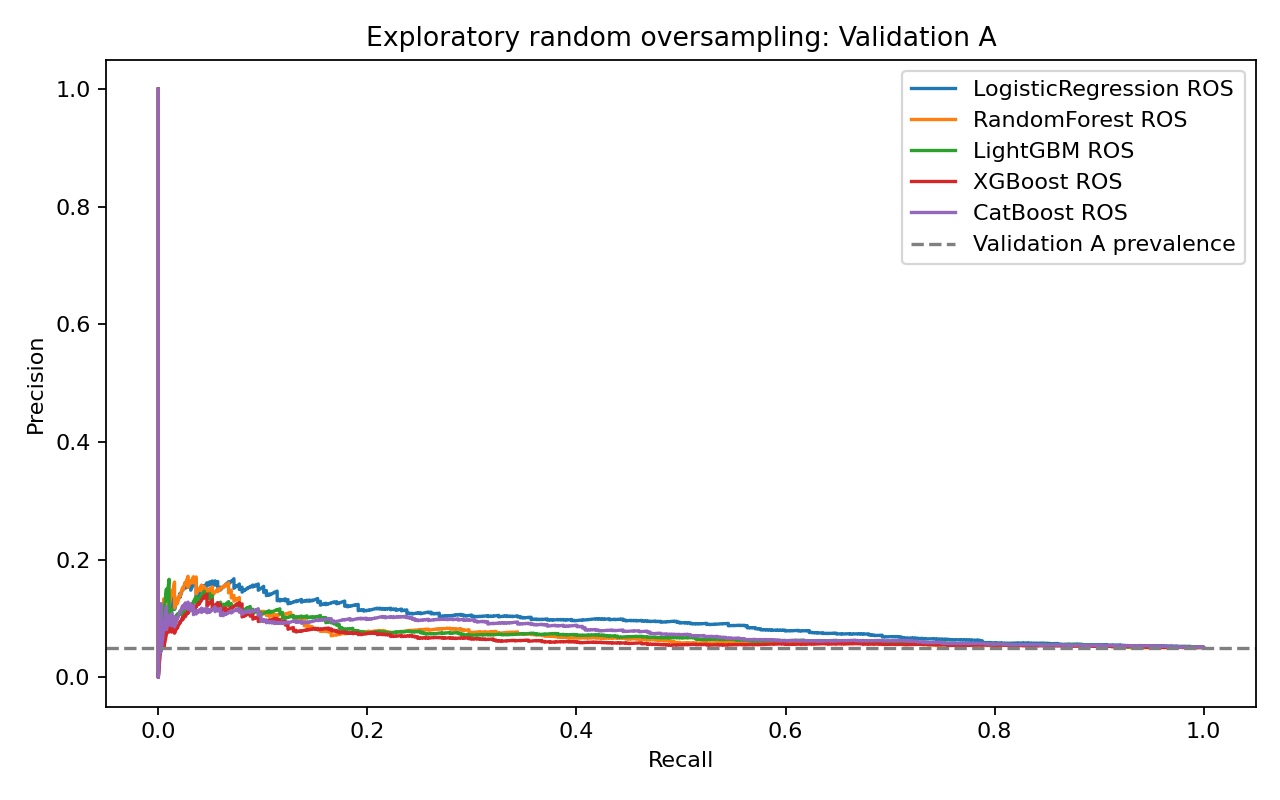

Results: outputs\tables\ml_random_oversampling\20261111_160816_219035
Exploratory extension complete. B/Test and frozen decision untouched.


In [11]:
oversampled_metrics = pd.DataFrame(results.values())
assert len(oversampled_metrics) == 5 and oversampled_metrics.model.is_unique
baselines = baseline_comparison.loc[baseline_comparison.model.isin(registry)].copy()
assert len(baselines) == 5
baselines["configuration"] = "baseline"
comparison = pd.concat([baselines, oversampled_metrics], ignore_index=True)
comparison.to_csv(tables / "ten_configuration_comparison.csv", index=False)
pairwise = baselines.merge(oversampled_metrics, on="model", suffixes=("_baseline", "_oversampled"), validate="one_to_one")
changes = pairwise[["model"]].copy()
for metric in ["AP", "ROC_AUC", "Brier", "LogLoss"]:
    changes[metric + "_baseline"] = pairwise[metric + "_baseline"]
    changes[metric + "_oversampled"] = pairwise[metric + "_oversampled"]
    changes[metric + "_change"] = pairwise[metric + "_oversampled"] - pairwise[metric + "_baseline"]
changes.to_csv(tables / "oversampling_changes.csv", index=False)
display(changes)
all_predictions = pd.concat(prediction_parts.values(), ignore_index=True)
assert len(all_predictions) == 5 * len(val)
assert not all_predictions.duplicated(["model", "order_id"]).any()
for name, group in all_predictions.groupby("model"):
    np.testing.assert_array_equal(group.order_id, val.order_id)
    np.testing.assert_array_equal(group.y_true, y_val)
fig, ax = plt.subplots(figsize=(8, 5))
for name, group in all_predictions.groupby("model", sort=False):
    precision, recall, _ = precision_recall_curve(group.y_true, group.probability)
    ax.plot(recall, precision, label=name + " ROS")
ax.axhline(float(y_val.mean()), linestyle="--", color="gray", label="Validation A prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Exploratory random oversampling: Validation A")
ax.legend()
fig.tight_layout()
path = figures / "validation_a_pr_curve.png"
fig.savefig(path, dpi=160)
display(Image(filename=str(path)))
plt.close(fig)
for name, digest in hashes.items():
    assert file_hash(ROOT / name) == digest
for record in registry.values():
    assert file_hash(ROOT / record["pipeline"]) == record["pipeline_sha256"]
(tables / "completion.json").write_text(json.dumps(dict(status="completed", models=list(results), validation_a_only=True, test_predicted=False, frozen_decision_changed=False), indent=2), encoding="utf-8")
print("Results:", tables.relative_to(ROOT))
print("Exploratory extension complete. B/Test and frozen decision untouched.")
